# Transaction Fraud Detection

**Question:** can a model flag fraudulent card transactions when fraud is rare, and what is the trade-off between catching fraud and flagging legitimate customers?

**Data:** an e-commerce transaction dataset (the IEEE-CIS fraud detection data): 590,540 labeled training transactions, of which 20,663 (3.5%) are fraud, plus 506,691 unlabeled test transactions. The raw files are 1.3 GB; this notebook uses a 13-column cleaned version (amount, product code, card details, email domain, device type).

**Approach:** compare fraud rates across product, card and device types; train logistic regression and four random forest variants with different ways of handling the imbalance (none, class weights, undersampling, oversampling); compare them on a held-out validation set using AUC, recall and precision; then score the unlabeled test set with the best model.

**Key results:**
- Accuracy is misleading here: logistic regression is 96.5% accurate but catches no fraud at all, exactly the same as never flagging anything.
- The undersampled random forest has the best AUC (0.772) and catches 66.0% of fraud, but only 8.0% of the transactions it flags are fraud.
- The plain random forest is the opposite: 40.4% of its flags are fraud, but it catches only 16.9% of fraud.
- Transaction amount and card details are the strongest signals. Fraud rates run highest for product code C (11.7%) and for mobile devices (10.2%).

**Tools:** Python (pandas, scikit-learn, matplotlib, seaborn)

**Context:** master's coursework (DSC680, Project 3), cleaned up for this portfolio.

## 1. Load and prepare the data
The raw files (`train_transaction.csv`, 652 MB, and `test_transaction.csv`, 585 MB) are too large to publish, so this notebook builds the smaller cleaned files from them when they are present, and otherwise loads the cleaned files that are included. See `ORIGINAL_DATA_NOTE.md` for the sizes of the original data.

In [1]:
# import required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, confusion_matrix, roc_curve

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)   # fixed seed so the resampling below gives the same result every run

In [2]:
KEEP_COLS = ['TransactionID', 'isFraud', 'TransactionDate', 'TransactionAmt', 'ProductCD',
             'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'P_emaildomain', 'DeviceType']

def build_clean(transaction_file, identity_file):
    # merge each transaction with its device type, turn the seconds counter into a date, keep a smaller set of columns
    df = pd.read_csv(transaction_file).merge(pd.read_csv(identity_file, usecols=['TransactionID', 'DeviceType']),
                                             on='TransactionID', how='left')
    df['TransactionDate'] = pd.Timestamp('2017-12-01') + pd.to_timedelta(df['TransactionDT'], unit='s')
    return df[[c for c in KEEP_COLS if c in df.columns]].rename(columns={'card4': 'CardType'})

if os.path.exists('train_transaction.csv') and os.path.exists('test_transaction.csv'):
    train_df = build_clean('train_transaction.csv', 'train_identity.csv')
    test_df = build_clean('test_transaction.csv', 'test_identity.csv')
    train_df.to_csv('df_fraud_train_clean.csv', index=False)
    test_df.to_csv('df_fraud_test_clean.csv', index=False)
    print('Built the cleaned files from the raw data.')
else:
    train_df = pd.read_csv('df_fraud_train_clean.csv', parse_dates=['TransactionDate'])
    test_df = pd.read_csv('df_fraud_test_clean.csv', parse_dates=['TransactionDate'])
    print('Raw files not found: loaded the cleaned files.')

print(f'Training transactions: {len(train_df):,}   Unlabeled test transactions: {len(test_df):,}')
train_df.head()

Raw files not found: loaded the cleaned files.
Training transactions: 590,540   Unlabeled test transactions: 506,691


,TransactionID,isFraud,TransactionDate,TransactionAmt,ProductCD,card1,card2,card3,CardType,card5,card6,P_emaildomain,DeviceType
0,2987000,0,2017-12-02 00:00:00,68.5,W,13926,NaN,150.0,discover,142.0,credit,NaN,NaN
1,2987001,0,2017-12-02 00:00:01,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,gmail.com,NaN
2,2987002,0,2017-12-02 00:01:09,59.0,W,4663,490.0,150.0,visa,166.0,debit,outlook.com,NaN
3,2987003,0,2017-12-02 00:01:39,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,yahoo.com,NaN
4,2987004,0,2017-12-02 00:01:46,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,gmail.com,mobile


## 2. Explore the data

Fraudulent transactions: 20,663 of 590,540 (3.5%)
Training dates: Dec 02, 2017 to Jun 01, 2018
Test dates:     Jul 02, 2018 to Dec 31, 2018


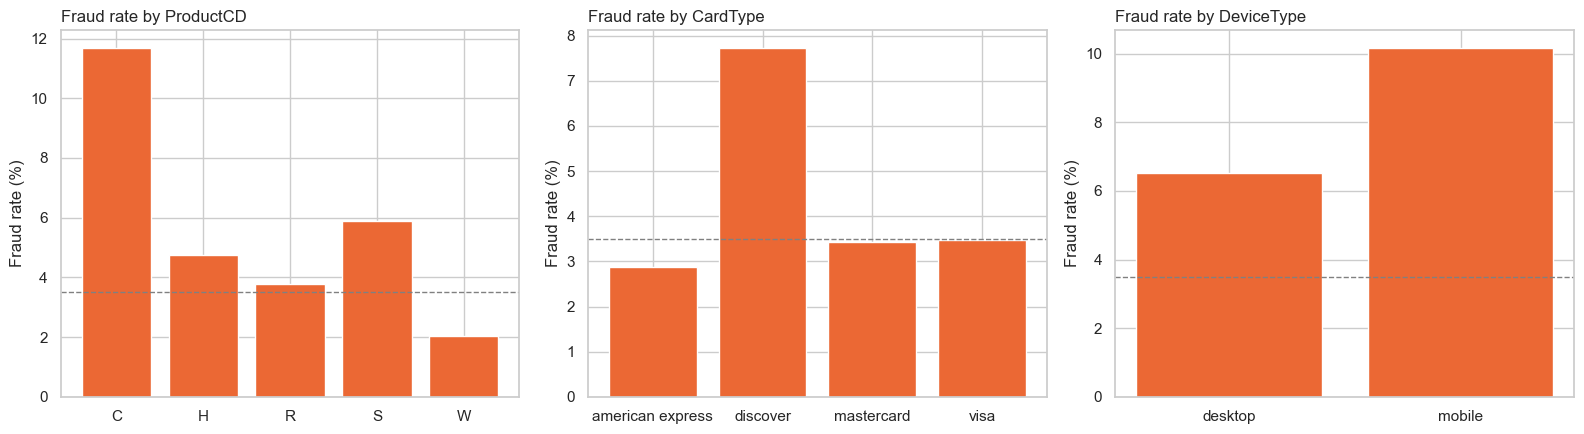

Fraud rate by ProductCD: {'C': 11.7, 'H': 4.8, 'R': 3.8, 'S': 5.9, 'W': 2.0}
Fraud rate by CardType: {'american express': 2.9, 'discover': 7.7, 'mastercard': 3.4, 'visa': 3.5}
Fraud rate by DeviceType: {'desktop': 6.5, 'mobile': 10.2}


In [3]:
fraud_rate = train_df['isFraud'].mean()
print(f"Fraudulent transactions: {train_df['isFraud'].sum():,} of {len(train_df):,} ({fraud_rate:.1%})")
print(f"Training dates: {train_df['TransactionDate'].min():%b %d, %Y} to {train_df['TransactionDate'].max():%b %d, %Y}")
print(f"Test dates:     {test_df['TransactionDate'].min():%b %d, %Y} to {test_df['TransactionDate'].max():%b %d, %Y}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['ProductCD', 'CardType', 'DeviceType']):
    rate = train_df.groupby(col)['isFraud'].agg(['mean', 'size'])
    ax.bar(rate.index.astype(str), rate['mean'] * 100, color='#eb6834')
    ax.axhline(fraud_rate * 100, color='grey', linestyle='--', lw=1)
    ax.set_title(f'Fraud rate by {col}', loc='left'); ax.set_ylabel('Fraud rate (%)')
plt.tight_layout()
plt.show()

for col in ['ProductCD', 'CardType', 'DeviceType']:
    print(f'Fraud rate by {col}:', (train_df.groupby(col)['isFraud'].mean() * 100).round(1).to_dict())

## 3. Prepare features
Missing numbers are filled with the median and missing categories with the most common value, then categories are converted to numbers. To keep training time reasonable, models are developed on a stratified sample of 50,000 transactions (same 3.5% fraud rate), split 80/20 into training and validation sets.

In [4]:
target, drop_cols = 'isFraud', ['TransactionID', 'TransactionDate']
X = train_df.drop(columns=[target] + drop_cols)
y = train_df[target]
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')
X[num_cols] = num_imputer.fit_transform(X[num_cols])
X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])
label_encoders = {}
for col in cat_cols:
    label_encoders[col] = LabelEncoder().fit(X[col])
    X[col] = label_encoders[col].transform(X[col])

X_sub, _, y_sub, _ = train_test_split(X, y, train_size=50000, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_sub, y_sub, test_size=0.2, stratify=y_sub, random_state=42)
print(f'Training: {len(X_train):,} ({y_train.sum():,} fraud)   Validation: {len(X_val):,} ({y_val.sum():,} fraud)')

Training: 40,000 (1,400 fraud)   Validation: 10,000 (350 fraud)


## 4. Train five models
Fraud is only 3.5% of transactions, so a model can be 96.5% accurate by never flagging anything. Several ways of handling that imbalance are compared: no adjustment, class weights, undersampling the legitimate transactions, and oversampling the fraud.

In [5]:
# logistic regression and a plain random forest (with 3-fold cross-validation on the training set)
lr_model = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
rf_cv_model = RandomForestClassifier(n_estimators=100, random_state=42)
cv_scores = cross_val_score(rf_cv_model, X_train, y_train, cv=3, scoring='roc_auc')
rf_cv_model.fit(X_train, y_train)
print(f'Random forest 3-fold CV AUC on the training set: {cv_scores.mean():.3f} ({np.round(cv_scores, 3)})')

# random forest with balanced class weights
rf_balanced = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42).fit(X_train, y_train)

# undersampling: keep every fraud case and an equal-sized random sample of legitimate transactions
fraud_idx = y_train[y_train == 1].index
legit_idx = y_train[y_train == 0].index
under_idx = np.concatenate([fraud_idx, rng.choice(legit_idx, len(fraud_idx), replace=False)])
rf_under = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train.loc[under_idx], y_train.loc[under_idx])

# oversampling: repeat fraud cases at random until they match the legitimate transactions
over_idx = np.concatenate([legit_idx, rng.choice(fraud_idx, len(legit_idx), replace=True)])
rf_over = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train.loc[over_idx], y_train.loc[over_idx])

Random forest 3-fold CV AUC on the training set: 0.745 ([0.759 0.73  0.747])


## 5. Compare the models on the validation set

In [6]:
models = {'Logistic regression': lr_model, 'Random forest': rf_cv_model, 'RF, balanced weights': rf_balanced,
          'RF, undersampling': rf_under, 'RF, oversampling': rf_over}
rows = []
for name, model in models.items():
    pred = model.predict(X_val); prob = model.predict_proba(X_val)[:, 1]
    rows.append({'model': name, 'AUC': roc_auc_score(y_val, prob), 'accuracy': accuracy_score(y_val, pred),
                 'fraud caught (recall)': recall_score(y_val, pred),
                 'flags that are fraud (precision)': precision_score(y_val, pred, zero_division=0),
                 'transactions flagged': int(pred.sum())})
results_df = pd.DataFrame(rows).set_index('model')
print(f'Baseline accuracy if no transaction is ever flagged: {1 - y_val.mean():.1%}')
results_df.round(3)

Baseline accuracy if no transaction is ever flagged: 96.5%


,AUC,accuracy,fraud caught (recall),flags that are fraud (precision),transactions flagged
model,,,,,
Logistic regression,0.683,0.965,0.000,0.000,0
Random forest,0.758,0.962,0.169,0.404,146
"RF, balanced weights",0.760,0.954,0.191,0.275,244
"RF, undersampling",0.772,0.723,0.660,0.080,2881
"RF, oversampling",0.764,0.945,0.243,0.229,371


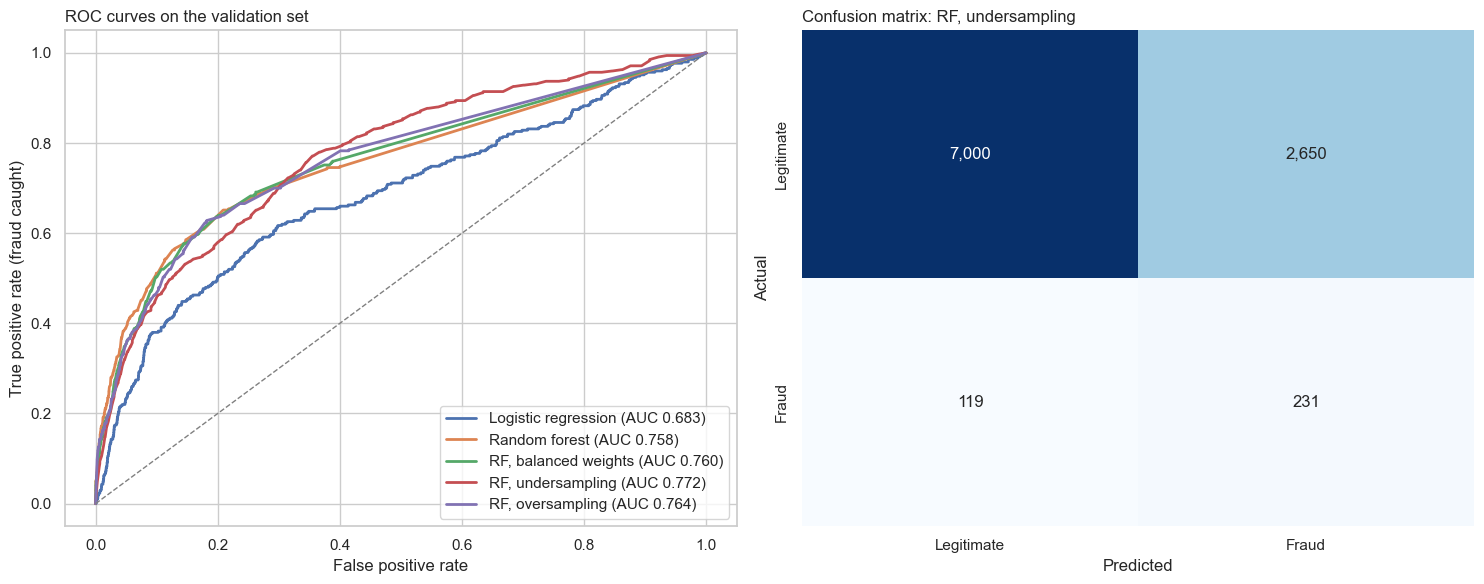

Best model by AUC: RF, undersampling


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_val, model.predict_proba(X_val)[:, 1])
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC {results_df.loc[name, 'AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color='grey', linestyle='--', lw=1)
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate (fraud caught)')
axes[0].set_title('ROC curves on the validation set', loc='left'); axes[0].legend(loc='lower right')

best_name = results_df['AUC'].idxmax()
cm = confusion_matrix(y_val, models[best_name].predict(X_val))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'])
axes[1].set_title(f'Confusion matrix: {best_name}', loc='left'); axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()
print('Best model by AUC:', best_name)

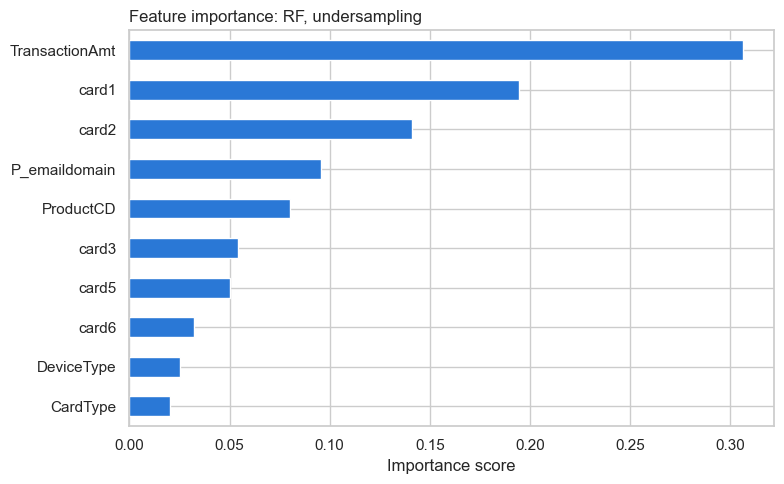

TransactionAmt    0.306
card1             0.194
card2             0.141
P_emaildomain     0.096
ProductCD         0.080
card3             0.054
card5             0.050
card6             0.032
DeviceType        0.025
CardType          0.020
dtype: float64

In [8]:
# which features the best model relies on
importances = pd.Series(models[best_name].feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', figsize=(8, 5), color='#2a78d6')
plt.title(f'Feature importance: {best_name}', loc='left'); plt.xlabel('Importance score')
plt.tight_layout(); plt.show()
importances.sort_values(ascending=False).round(3)

## 6. Score the unlabeled test transactions

In [9]:
X_test = test_df.drop(columns=drop_cols)
X_test[num_cols] = num_imputer.transform(X_test[num_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])
for col in cat_cols:   # categories never seen in training get -1
    known = set(label_encoders[col].classes_)
    X_test[col] = [label_encoders[col].transform([v])[0] if v in known else -1 for v in X_test[col]]

test_df['isFraud_probability'] = models[best_name].predict_proba(X_test[X.columns])[:, 1]
test_df[['TransactionID', 'isFraud_probability']].to_csv('fraud_predictions_test.csv', index=False)
print(f"Scored {len(test_df):,} test transactions with {best_name}; "
      f"{(test_df['isFraud_probability'] >= 0.5).mean():.1%} have a fraud probability of 50% or more.")

Scored 506,691 test transactions with RF, undersampling; 31.0% have a fraud probability of 50% or more.


## Findings
- **Fraud is rare, so accuracy hides everything.** With 3.5% fraud, never flagging a transaction is 96.5% accurate. Logistic regression lands exactly there (96.5% accuracy, zero fraud caught), so it learned nothing useful. AUC, recall and precision are the measures that matter.
- **Handling the imbalance changes what a model is good at.** On 10,000 validation transactions (350 fraud):
    - **Undersampled random forest:** best AUC (0.772), catches 66.0% of fraud (231 of 350), but flags 2,881 transactions, so only 8.0% of its flags are fraud.
    - **Plain random forest:** flags only 146 transactions and 40.4% of them are fraud, but it catches just 16.9% of fraud.
    - **Class weights and oversampling** fall in between (19.1% and 24.3% of fraud caught).
- **The right model depends on the cost of each mistake.** A review team that can only check a few hundred transactions a day would prefer the precise plain random forest; a business where missed fraud is very expensive would accept more false alarms. At the default 50% cutoff, the undersampled model flags 31.0% of the test transactions, which is too many to review, so in practice its cutoff would need to be raised.
- **What drives the predictions:** transaction amount (importance 0.306) and card details (card1 0.194, card2 0.141) lead, followed by email domain and product code. Fraud rates are highest for product code C (11.7% vs. 2.0% for W), Discover cards (7.7%), and mobile devices (10.2% vs. 6.5% for desktop).
- **Limitations and next steps:**
    - Device type is only known for 23.8% of transactions, and those transactions are far riskier (8.0% fraud vs. 2.1% when it is unknown). Filling the blanks with the most common value hides that signal; flagging "unknown" as its own category would likely help.
    - Models were developed on a 50,000-transaction sample and 10 of the original 434 columns as features. Using more of the data and features, and a gradient boosting model, are the obvious next steps.
    - The training data covers December 2017 to June 2018 and the test data July to December 2018, so a time-based validation split would better reflect how the model would be used.

**Cleanup note:** the original notebook had no written summary and used unseeded random sampling, so its results changed slightly on every run (for example the undersampled model's AUC was 0.770 in the saved output and 0.772 here). This version fixes the seed, adds recall and precision, and runs from the cleaned files when the raw files are not present. The original notebook is in `earlier_versions/`.